<a href="https://colab.research.google.com/github/raksd/LLM_finetuning/blob/main/GRPO_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip uninstall -y torchao
!pip install -q trl peft datasets accelerate

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 927.2/927.2 kB 19.7 MB/s eta 0:00:00


In [2]:
import re, torch
from datasets import load_dataset

SYSTEM = "Solve the math problem. Think step by step, then give the final number as <answer>NUMBER</answer>."

def prep(ex):
    return {
        "prompt": [{"role": "system", "content": SYSTEM},
                   {"role": "user", "content": ex["question"]}],
        "gold": ex["answer"].split("####")[-1].strip().replace(",", ""),
    }

raw = load_dataset("openai/gsm8k", "main")
train_ds = raw["train"].map(prep, remove_columns=["question", "answer"])
test_ds  = raw["test"].select(range(100)).map(prep, remove_columns=["question", "answer"])

print("Train size:", len(train_ds), "| Test size:", len(test_ds))
print("\n--- RAW example ---")
print("Question:", raw["train"][0]["question"])
print("Full solution:", raw["train"][0]["answer"])
print("\n--- AFTER prep() ---")
print("Prompt sent to model:", train_ds[0]["prompt"])
print("Gold answer kept:", train_ds[0]["gold"])

README.md:   0%|          | 0.00/7.93k [00:00<?, ?B/s]

main/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.31MB            

main/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

main/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  419kB            

main/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

Map:   0%|          | 0/7473 [00:00<?, ? examples/s]

Map:   0%|          | 0/100 [00:00<?, ? examples/s]

Train size: 7473 | Test size: 100

--- RAW example ---
Question: Natalia sold clips to 48 of her friends in April, and then she sold half as many clips in May. How many clips did Natalia sell altogether in April and May?
Full solution: Natalia sold 48/2 = <<48/2=24>>24 clips in May.
Natalia sold 48+24 = <<48+24=72>>72 clips altogether in April and May.
#### 72

--- AFTER prep() ---
Prompt sent to model: [{'content': 'Solve the math problem. Think step by step, then give the final number as <answer>NUMBER</answer>.', 'role': 'system'}, {'content': 'Natalia sold clips to 48 of her friends in April, and then she sold half as many clips in May. How many clips did Natalia sell altogether in April and May?', 'role': 'user'}]
Gold answer kept: 72


In [3]:
def extract(text):
    m = re.search(r"<answer>\s*(-?[\d,\.]+)\s*</answer>", text)
    return m.group(1).replace(",", "").rstrip(".") if m else None

def correctness_reward(completions, gold, **kw):
    return [2.0 if extract(c[0]["content"]) == g else 0.0 for c, g in zip(completions, gold)]

def format_reward(completions, **kw):
    return [0.5 if extract(c[0]["content"]) is not None else 0.0 for c in completions]

# Fake model answers so you can see the scoring
fake = [
    [{"role": "assistant", "content": "5+3=8. <answer>8</answer>"}],    # right + formatted
    [{"role": "assistant", "content": "5+3=9. <answer>9</answer>"}],    # wrong + formatted
    [{"role": "assistant", "content": "The answer is 8."}],              # right but no tags
]
gold = ["8", "8", "8"]
print("correctness:", correctness_reward(fake, gold))   # expect [2.0, 0.0, 0.0]
print("format:     ", format_reward(fake))              # expect [0.5, 0.5, 0.0]

correctness: [2.0, 0.0, 0.0]
format:      [0.5, 0.5, 0.0]


In [11]:
from transformers import AutoModelForCausalLM, AutoTokenizer

name = "Qwen/Qwen2.5-0.5B-Instruct"
tok = AutoTokenizer.from_pretrained(name)
tok.padding_side = "left"


# # new code but it takes too long!!
# def accuracy(model, ds, show=3):
#     model.eval(); correct = tagged = 0
#     for i, ex in enumerate(ds):
#         ids = tok.apply_chat_template(ex["prompt"], add_generation_prompt=True,
#                                       return_tensors="pt", return_dict=True).to(model.device)
#         with torch.no_grad():
#             out = model.generate(**ids, max_new_tokens=256, do_sample=False)
#         text = tok.decode(out[0][ids["input_ids"].shape[1]:], skip_special_tokens=True)
#         pred = extract(text)
#         tagged += pred is not None
#         correct += pred == ex["gold"]
#     print(f"correct: {correct}/{len(ds)} | used <answer> tags: {tagged}/{len(ds)}")
#     return correct / len(ds)

# def accuracy(model, ds, show=3):
#     model.eval(); correct = 0
#     for i, ex in enumerate(ds):
#         ids = tok.apply_chat_template(ex["prompt"], add_generation_prompt=True,
#                                       return_tensors="pt", return_dict=True).to(model.device)
#         with torch.no_grad():
#             out = model.generate(**ids, max_new_tokens=256, do_sample=False)
#         text = tok.decode(out[0][ids["input_ids"].shape[1]:], skip_special_tokens=True)
#         pred = extract(text)
#         ok = pred == ex["gold"]
#         correct += ok
#         if i < show:
#             print(f"\n--- Problem {i+1} ---")
#             print("Q:", ex["prompt"][1]["content"][:200])
#             print("Model wrote:", text[:400])
#             print(f"Extracted: {pred} | Gold: {ex['gold']} | {'✅' if ok else '❌'}")
#     return correct / len(ds)


#Most updated code as a batch

def accuracy(model, ds, batch_size=16, max_new_tokens=256):
    model.eval(); correct = tagged = 0
    prompts = [tok.apply_chat_template(ex["prompt"], add_generation_prompt=True, tokenize=False) for ex in ds]
    golds = ds["gold"]
    for i in range(0, len(prompts), batch_size):
        batch = tok(prompts[i:i+batch_size], return_tensors="pt", padding=True).to(model.device)
        with torch.no_grad():
            out = model.generate(**batch, max_new_tokens=max_new_tokens, do_sample=False,
                                 pad_token_id=tok.pad_token_id)
        texts = tok.batch_decode(out[:, batch["input_ids"].shape[1]:], skip_special_tokens=True)
        for text, gold in zip(texts, golds[i:i+batch_size]):
            pred = extract(text)
            tagged += pred is not None
            correct += pred == gold
    print(f"correct: {correct}/{len(ds)} | used <answer> tags: {tagged}/{len(ds)}")
    return correct / len(ds)

base = AutoModelForCausalLM.from_pretrained(name, device_map={"": 0}, torch_dtype=torch.float16)
results = {"base": accuracy(base, test_ds)}
print("\nBase accuracy:", results["base"])

import gc; del base; gc.collect(); torch.cuda.empty_cache()

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

correct: 4/100 | used <answer> tags: 5/100

Base accuracy: 0.04


In [5]:
from peft import LoraConfig
from trl import GRPOConfig, GRPOTrainer

state = {"n": 0}

def correctness_logged(prompts, completions, gold, **kw):
    scores = correctness_reward(completions, gold)
    state["n"] += 1
    if state["n"] % 5 == 1:   # print every 5th batch
        print(f"\n===== Scoring batch {state['n']} =====")
        print("Question:", prompts[0][-1]["content"][:150])
        print("Gold:", gold[0])
        for c, s in zip(completions, scores):
            print(f"  extracted={extract(c[0]['content'])!s:>8} | score={s}")
        print("  Sample attempt:", completions[0][0]["content"][:300].replace("\n", " "))
    return scores

cfg = GRPOConfig(
    output_dir="./grpo-qwen",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    num_generations=8,
    max_completion_length=256,
    gradient_accumulation_steps=2,
    max_steps=200,
    logging_steps=1,          # print metrics every step
    fp16=True,
    save_strategy="no",
    report_to="none",
)

trainer = GRPOTrainer(
    model=name,
    reward_funcs=[correctness_logged, format_reward],
    args=cfg,
    train_dataset=train_ds,
    peft_config=LoraConfig(r=16, lora_alpha=32,
                           target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
                           task_type="CAUSAL_LM"),
)
trainer.train()

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]


===== Scoring batch 1 =====
Question: Ahmed and Emily are having a contest to see who can get the best grade in the class. There have been 9 assignments and Ahmed has a 91 in the class. Em
Gold: 100
  extracted=      13 | score=0.0
  extracted=    None | score=0.0
  extracted=    None | score=0.0
  extracted=    None | score=0.0
  extracted=    None | score=0.0
  extracted=    None | score=0.0
  extracted=    None | score=0.0
  extracted=    None | score=0.0
  extracted=    None | score=0.0
  extracted=    None | score=0.0
  extracted=    None | score=0.0
  extracted=    None | score=0.0
  extracted=    None | score=0.0
  extracted=    None | score=0.0
  extracted=    None | score=0.0
  extracted=    None | score=0.0
  Sample attempt: Now you have to get it count so you will have a remainder of 1, but the only way the remainder can be 1 is if both equations are divisible by the divisor and the divisor is 9. Also, since 91+90+1=181, Emily has beaten Ahmed, which is aWhole number. The m

Step,Training Loss
1,0.020665
2,0.058709
3,-0.039417
4,0.160194
5,0.000000
6,-0.067822
7,-0.000506
8,0.161402
9,0.155315
10,-0.000554



===== Scoring batch 6 =====
Question: There are 84 people waiting in line to ride a roller coaster at an amusement park.  The roller coaster has 7 cars, and each car seats 2 people.  How m
Gold: 6
  extracted=    None | score=0.0
  extracted=      14 | score=0.0
  extracted=       6 | score=2.0
  extracted=       6 | score=2.0
  extracted=      42 | score=0.0
  extracted=    None | score=0.0
  extracted=       7 | score=0.0
  extracted=       4 | score=0.0
  extracted=    None | score=0.0
  extracted=      14 | score=0.0
  extracted=    None | score=0.0
  extracted=    None | score=0.0
  extracted=    None | score=0.0
  extracted=       8 | score=0.0
  extracted=    None | score=0.0
  extracted=    None | score=0.0
  Sample attempt: There will have to be 84 / 7 = 12 runs of the roller coaster. Each run will have been able to seat 2 * 7 = 14 people. Therefore, the ride operator has to run the roller coaster 12 * 14 = 168 times. 168 is the final answer.

===== Scoring batch 11 =====
Que

TrainOutput(global_step=200, training_loss=0.03455129849724472, metrics={'train_runtime': 2583.1884, 'train_samples_per_second': 1.239, 'train_steps_per_second': 0.077, 'total_flos': 0.0, 'train_loss': 0.03455129849724472, 'epoch': 0.05353319057815846})

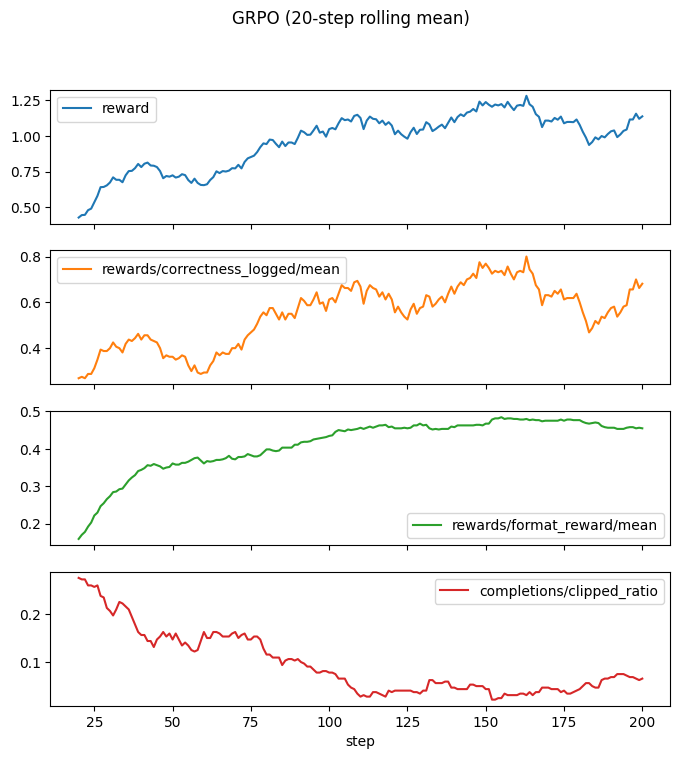

In [12]:
# import matplotlib.pyplot as plt

# logs = trainer.state.log_history
# steps   = [l["step"] for l in logs if "reward" in l]
# rewards = [l["reward"] for l in logs if "reward" in l]
# if not rewards:
#     print("Available log keys:", set(k for l in logs for k in l))
# else:
#     plt.plot(steps, rewards); plt.xlabel("step"); plt.ylabel("mean reward")
#     plt.title("GRPO: average reward during training"); plt.show()

# results["grpo"] = accuracy(trainer.model, test_ds)
# print(results)


import pandas as pd, matplotlib.pyplot as plt
df = pd.DataFrame([l for l in trainer.state.log_history if "reward" in l]).set_index("step")
cols = ["reward", "rewards/correctness_logged/mean", "rewards/format_reward/mean", "completions/clipped_ratio"]
df[cols].rolling(20).mean().plot(subplots=True, figsize=(8, 8), title="GRPO (20-step rolling mean)")
plt.show()

In [7]:
trainer.model.print_trainable_parameters()

trainable params: 2,162,688 || all params: 496,195,456 || trainable%: 0.4359


In [8]:
# @title
for l in trainer.state.log_history:
    if "reward" in l:
        print(l["step"], {k: round(v, 3) for k, v in l.items() if "reward" in k or "clipped" in k})

1 {'completions/clipped_ratio': 0.312, 'rewards/correctness_logged/mean': 0.0, 'rewards/correctness_logged/std': 0.0, 'rewards/format_reward/mean': 0.031, 'rewards/format_reward/std': 0.125, 'reward': 0.031, 'reward_std': 0.125, 'frac_reward_zero_std': 0.5}
2 {'completions/clipped_ratio': 0.438, 'rewards/correctness_logged/mean': 0.125, 'rewards/correctness_logged/std': 0.5, 'rewards/format_reward/mean': 0.094, 'rewards/format_reward/std': 0.202, 'reward': 0.219, 'reward_std': 0.632, 'frac_reward_zero_std': 0.0}
3 {'completions/clipped_ratio': 0.25, 'rewards/correctness_logged/mean': 0.25, 'rewards/correctness_logged/std': 0.683, 'rewards/format_reward/mean': 0.125, 'rewards/format_reward/std': 0.224, 'reward': 0.375, 'reward_std': 0.847, 'frac_reward_zero_std': 0.5}
4 {'completions/clipped_ratio': 0.25, 'rewards/correctness_logged/mean': 0.25, 'rewards/correctness_logged/std': 0.683, 'rewards/format_reward/mean': 0.094, 'rewards/format_reward/std': 0.202, 'reward': 0.344, 'reward_std'

GRPO's logged reward rose from about 0.4 to about 1.1 over 200 steps. Breaking it down, the format reward saturated and truncated answers dropped to nearly zero, so the model first learned to follow the output format. Correctness per batch rose from roughly 14% to 34%, but part of that gain comes from answers that used to be cut off now counting. To be fair I compared base and trained models on the same held-out problems."

Our extract() function only looks for <answer>number</answer>. If the tag is missing, it returns None, and the correctness reward is 0 even when the math is right. That's why the format reward exists.